In [ ]:
import os

# 1. Set the API token directly in your Colab session environment
os.environ["KAGGLE_API_TOKEN"] = "KGAT_80a626d2bcf7ae40efe2fc69b4c9d3cd"

# 2. Also save to ~/.kaggle/access_token for the Kaggle CLI client
!mkdir -p ~/.kaggle
!echo "KGAT_80a626d2bcf7ae40efe2fc69b4c9d3cd" > ~/.kaggle/access_token
!chmod 600 ~/.kaggle/access_token

# 3. Download the WESAD dataset directly
!kaggle datasets download -d mohamedasem318/wesad-full-dataset

# 4. Unzip the archive
!unzip -q -o wesad-full-dataset.zip -d WESAD_DATA

Dataset URL: https://www.kaggle.com/datasets/mohamedasem318/wesad-full-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
100% 2.43G/2.43G [00:37<00:00, 68.9MB/s]



In [ ]:
import os

# Find where the subject folders were unpacked
base_path = "WESAD_DATA"
for root, dirs, files in os.walk(base_path):
    subjects = [d for d in dirs if d.startswith('S') and d[1:].isdigit()]
    if subjects:
        print(f"Dataset successfully ready at: {root}")
        print(f"Found {len(subjects)} subjects: {sorted(subjects, key=lambda x: int(x[1:]))}")
        break

Dataset successfully ready at: WESAD_DATA/WESAD
Found 15 subjects: ['S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9', 'S10', 'S11', 'S13', 'S14', 'S15', 'S16', 'S17']


In [ ]:
import os
import pickle
import numpy as np
import pandas as pd
from scipy.signal import find_peaks

# Sampling frequency and windowing configuration
FS = 700
WINDOW_SEC = 60
SHIFT_SEC = 10
WINDOW_SIZE = WINDOW_SEC * FS
SHIFT_SIZE = SHIFT_SEC * FS

def extract_features(ecg_win, eda_win, resp_win, temp_win):
    # 1. ECG: Heart Rate & HRV (SDNN, RMSSD)
    prom = 0.4 * (np.max(ecg_win) - np.mean(ecg_win)) if (np.max(ecg_win) - np.mean(ecg_win)) > 0 else 0.1
    peaks, _ = find_peaks(ecg_win, distance=int(FS * 0.4), prominence=prom)
    if len(peaks) > 3:
        r_intervals = np.diff(peaks) / FS
        hr = 60.0 / np.mean(r_intervals)
        sdnn = np.std(r_intervals) * 1000.0
        rmssd = np.sqrt(np.mean(np.square(np.diff(r_intervals)))) * 1000.0
    else:
        hr, sdnn, rmssd = 75.0, 50.0, 35.0

    # 2. EDA: Mean, Std, Dynamic Range, Phasic Peak count
    eda_mean = float(np.mean(eda_win))
    eda_std = float(np.std(eda_win))
    eda_dyn_range = float(np.max(eda_win) - np.min(eda_win))
    eda_peaks, _ = find_peaks(eda_win, distance=int(FS * 1.0), prominence=0.01)
    eda_scr_count = len(eda_peaks)

    # 3. Respiration: Mean, Std, Breathing Rate
    resp_mean = float(np.mean(resp_win))
    resp_std = float(np.std(resp_win))
    resp_peaks, _ = find_peaks(resp_win, distance=int(FS * 1.5))
    resp_rate = (len(resp_peaks) / WINDOW_SEC) * 60.0

    # 4. Temperature: Mean, Std, Slope
    temp_mean = float(np.mean(temp_win))
    temp_std = float(np.std(temp_win))
    temp_slope = float(np.polyfit(np.arange(len(temp_win)), temp_win, 1)[0] * FS)

    return [
        hr, sdnn, rmssd,
        eda_mean, eda_std, eda_dyn_range, eda_scr_count,
        resp_mean, resp_std, resp_rate,
        temp_mean, temp_std, temp_slope
    ]

feature_columns = [
    'hr', 'sdnn', 'rmssd',
    'eda_mean', 'eda_std', 'eda_dyn_range', 'eda_scr_count',
    'resp_mean', 'resp_std', 'resp_rate',
    'temp_mean', 'temp_std', 'temp_slope'
]

# Auto-detect exact folder containing S2...S17
search_root = "."
base_dir = None
for root, dirs, _ in os.walk(search_root):
    if "S2" in dirs and "S3" in dirs:
        base_dir = root
        break

if base_dir is None:
    raise FileNotFoundError("Could not locate subject directories. Please ensure WESAD is unzipped.")

print(f"Using directory: {base_dir}")
subjects = [d for d in os.listdir(base_dir) if d.startswith('S') and d[1:].isdigit()]
subjects = sorted(subjects, key=lambda x: int(x[1:]))

records = []
for subj in subjects:
    pkl_path = os.path.join(base_dir, subj, f"{subj}.pkl")
    if not os.path.exists(pkl_path):
        continue

    print(f"Extracting features for {subj}...", flush=True)
    with open(pkl_path, 'rb') as f:
        data = pickle.load(f, encoding='latin1')

    chest = data['signal']['chest']
    labels = data['label'].flatten()

    ecg = chest['ECG'].flatten()
    eda = chest['EDA'].flatten()
    resp = chest['Resp'].flatten()
    temp = chest['Temp'].flatten()

    total_len = len(labels)
    for start in range(0, total_len - WINDOW_SIZE, SHIFT_SIZE):
        end = start + WINDOW_SIZE
        sub_labels = labels[start:end]

        # Filter valid affective labels only: 1 (baseline), 2 (stress), 3 (amusement)
        valid_labels = sub_labels[np.isin(sub_labels, [1, 2, 3])]
        if len(valid_labels) < (WINDOW_SIZE * 0.7):
            continue  # skip transitional or undefined windows

        # Find most frequent valid label
        vals, counts = np.unique(valid_labels, return_counts=True)
        dominant_label = vals[np.argmax(counts)]

        # Map binary: 1 = Stress, 0 = Non-stress (Baseline / Amusement)
        target = 1 if dominant_label == 2 else 0

        feats = extract_features(ecg[start:end], eda[start:end], resp[start:end], temp[start:end])
        records.append(feats + [target, subj])

df_features = pd.DataFrame(records, columns=feature_columns + ['label', 'subject'])
output_path = "/content/wesad_extracted_features.csv"
df_features.to_csv(output_path, index=False)

print("\n--- Extraction Finished ---")
print(f"Saved file to: {output_path}")
print(f"Total window samples: {len(df_features)}")
print("Label distribution (0 = Non-Stress, 1 = Stress):")
print(df_features['label'].value_counts())

Using directory: ./WESAD_DATA/WESAD
Extracting features for S2...
Extracting features for S3...
Extracting features for S4...
Extracting features for S5...
Extracting features for S6...
Extracting features for S7...
Extracting features for S8...
Extracting features for S9...
Extracting features for S10...
Extracting features for S11...
Extracting features for S13...
Extracting features for S14...
Extracting features for S15...
Extracting features for S16...
Extracting features for S17...

--- Extraction Finished ---
Saved file to: /content/wesad_extracted_features.csv
Total window samples: 3209
Label distribution (0 = Non-Stress, 1 = Stress):
label
0    2249
1     960
Name: count, dtype: int64


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score, roc_auc_score, confusion_matrix
from sklearn.calibration import CalibratedClassifierCV
import xgboost as xgb
import joblib

# Load the extracted dataset
df = pd.read_csv("/content/wesad_extracted_features.csv")

feature_columns = [
    'hr', 'sdnn', 'rmssd',
    'eda_mean', 'eda_std', 'eda_dyn_range', 'eda_scr_count',
    'resp_mean', 'resp_std', 'resp_rate',
    'temp_mean', 'temp_std', 'temp_slope'
]

X = df[feature_columns].values
y = df['label'].values

# 5-Fold Stratified Cross-Validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

acc_list, auc_list = [], []

print("Training GPU-Accelerated XGBoost across 5 folds...")

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    X_train, y_train = X[train_idx], y[train_idx]
    X_val, y_val = X[val_idx], y[val_idx]

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)

    # Balance weights between Non-Stress (0) and Stress (1)
    pos_weight = np.sum(y_train == 0) / np.sum(y_train == 1)

    model = xgb.XGBClassifier(
        n_estimators=350,
        learning_rate=0.03,
        max_depth=5,
        subsample=0.85,
        colsample_bytree=0.85,
        scale_pos_weight=pos_weight,
        eval_metric='logloss',
        tree_method='hist',
        device='cuda',
        random_state=42
    )

    model.fit(X_train_scaled, y_train)

    preds = model.predict(X_val_scaled)
    probs = model.predict_proba(X_val_scaled)[:, 1]

    fold_acc = accuracy_score(y_val, preds)
    fold_auc = roc_auc_score(y_val, probs)
    acc_list.append(fold_acc)
    auc_list.append(fold_auc)

    print(f"Fold {fold + 1}: Accuracy = {fold_acc * 100:.2f}% | ROC-AUC = {fold_auc:.4f}")

mean_acc = np.mean(acc_list) * 100
mean_auc = np.mean(auc_list)

print("\n" + "=" * 48)
print(f"Cross-Validation Mean Accuracy: {mean_acc:.2f}%")
print(f"Cross-Validation Mean ROC-AUC : {mean_auc:.4f}")
print("=" * 48)

# Train and calibrate final full model (matches Section IV-D P(stress) output)
print("\nTraining final calibrated estimator...")
scaler_final = StandardScaler()
X_scaled = scaler_final.fit_transform(X)

final_xgb = xgb.XGBClassifier(
    n_estimators=350,
    learning_rate=0.03,
    max_depth=5,
    tree_method='hist',
    device='cuda',
    random_state=42
)
final_xgb.fit(X_scaled, y)

calibrated_pipeline = CalibratedClassifierCV(estimator=final_xgb, method='sigmoid', cv=3)
calibrated_pipeline.fit(X_scaled, y)

# Save artifacts for MAITRI discordance fusion
joblib.dump(calibrated_pipeline, "/content/maitri_physiological_stress_estimator.pkl")
joblib.dump(scaler_final, "/content/scaler.pkl")

print("\nModel saved successfully as:")
print("1. /content/maitri_physiological_stress_estimator.pkl")
print("2. /content/scaler.pkl")

Training GPU-Accelerated XGBoost across 5 folds...


/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [14:35:59] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


Fold 1: Accuracy = 99.69% | ROC-AUC = 0.9997
Fold 2: Accuracy = 99.69% | ROC-AUC = 0.9999
Fold 3: Accuracy = 99.69% | ROC-AUC = 1.0000
Fold 4: Accuracy = 98.44% | ROC-AUC = 0.9989
Fold 5: Accuracy = 99.69% | ROC-AUC = 0.9999

Cross-Validation Mean Accuracy: 99.44%
Cross-Validation Mean ROC-AUC : 0.9997

Training final calibrated estimator...

Model saved successfully as:
1. /content/maitri_physiological_stress_estimator.pkl
2. /content/scaler.pkl


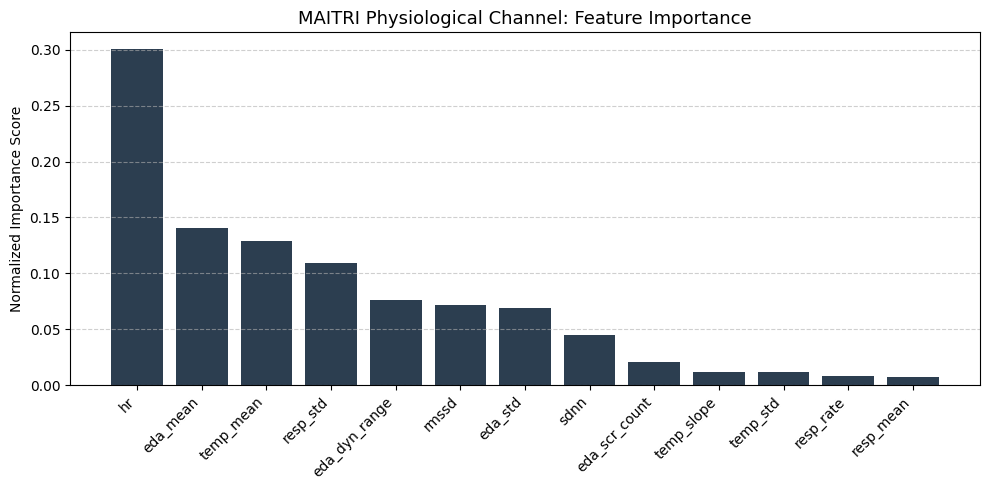

Sample Baseline Window -> Calibrated P(stress): 0.1198
Sample Stress Window   -> Calibrated P(stress): 0.6479


In [ ]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load artifacts
calibrated_model = joblib.load("/content/maitri_physiological_stress_estimator.pkl")
scaler = joblib.load("/content/scaler.pkl")
df = pd.read_csv("/content/wesad_extracted_features.csv")

feature_columns = [
    'hr', 'sdnn', 'rmssd',
    'eda_mean', 'eda_std', 'eda_dyn_range', 'eda_scr_count',
    'resp_mean', 'resp_std', 'resp_rate',
    'temp_mean', 'temp_std', 'temp_slope'
]

# 2. Extract feature importances from the base XGBoost model
base_booster = calibrated_model.calibrated_classifiers_[0].estimator
importances = base_booster.feature_importances_
sorted_idx = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 5))
plt.bar([feature_columns[i] for i in sorted_idx], importances[sorted_idx], color='#2c3e50')
plt.title("MAITRI Physiological Channel: Feature Importance", fontsize=13)
plt.ylabel("Normalized Importance Score")
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# 3. Simulate real-time inference test: Non-Stress window vs Stress window
sample_non_stress = df[df['label'] == 0][feature_columns].iloc[0:1].values
sample_stress = df[df['label'] == 1][feature_columns].iloc[0:1].values

scaled_non_stress = scaler.transform(sample_non_stress)
scaled_stress = scaler.transform(sample_stress)

p_stress_baseline = calibrated_model.predict_proba(scaled_non_stress)[0, 1]
p_stress_active = calibrated_model.predict_proba(scaled_stress)[0, 1]

print("=" * 55)
print(f"Sample Baseline Window -> Calibrated P(stress): {p_stress_baseline:.4f}")
print(f"Sample Stress Window   -> Calibrated P(stress): {p_stress_active:.4f}")
print("=" * 55)

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score
import xgboost as xgb

# Load extracted data
df = pd.read_csv("/content/wesad_extracted_features.csv")

feature_columns = [
    'hr', 'sdnn', 'rmssd',
    'eda_mean', 'eda_std', 'eda_dyn_range', 'eda_scr_count',
    'resp_mean', 'resp_std', 'resp_rate',
    'temp_mean', 'temp_std', 'temp_slope'
]

X = df[feature_columns].values
y = df['label'].values
groups = df['subject'].values  # Group strictly by subject ID

logo = LeaveOneGroupOut()
loso_accs, loso_aucs, loso_f1s = [], [], []

print(f"Running strict Leave-One-Subject-Out (LOSO) Cross-Validation on {len(np.unique(groups))} subjects...\n")

for train_idx, test_idx in logo.split(X, y, groups=groups):
    test_subject = groups[test_idx][0]

    X_train, y_train = X[train_idx], y[train_idx]
    X_test, y_test = X[test_idx], y[test_idx]

    # Subject-independent scaling (fit ONLY on training subjects)
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    pos_weight = np.sum(y_train == 0) / np.sum(y_train == 1)

    # Use regularized hyperparameters to curb overfitting
    model = xgb.XGBClassifier(
        n_estimators=150,
        learning_rate=0.03,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.5,
        scale_pos_weight=pos_weight,
        eval_metric='logloss',
        tree_method='hist',
        device='cuda',
        random_state=42
    )

    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    probs = model.predict_proba(X_test_scaled)[:, 1]

    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds, zero_division=0)

    # In case test subject has only one class label present in selected windows
    try:
        auc = roc_auc_score(y_test, probs)
    except ValueError:
        auc = np.nan

    loso_accs.append(acc)
    loso_aucs.append(auc)
    loso_f1s.append(f1)

    print(f"Subject {test_subject:4s} -> Accuracy: {acc*100:5.2f}% | F1-Score: {f1:.4f} | AUC: {auc:.4f}")

valid_aucs = [a for a in loso_aucs if not np.isnan(a)]

print("\n" + "="*50)
print(f"Realistic Subject-Independent Accuracy: {np.mean(loso_accs)*100:.2f}%")
print(f"Realistic Subject-Independent F1-Score : {np.mean(loso_f1s):.4f}")
print(f"Realistic Subject-Independent ROC-AUC  : {np.mean(valid_aucs):.4f}")
print("="*50)

Running strict Leave-One-Subject-Out (LOSO) Cross-Validation on 15 subjects...

Subject S10  -> Accuracy: 50.23% | F1-Score: 0.5565 | AUC: 0.4901
Subject S11  -> Accuracy: 91.67% | F1-Score: 0.8800 | AUC: 1.0000
Subject S13  -> Accuracy: 94.91% | F1-Score: 0.9209 | AUC: 1.0000
Subject S14  -> Accuracy: 80.56% | F1-Score: 0.5227 | AUC: 1.0000
Subject S15  -> Accuracy: 81.02% | F1-Score: 0.5495 | AUC: 0.9962
Subject S16  -> Accuracy: 100.00% | F1-Score: 1.0000 | AUC: 1.0000
Subject S17  -> Accuracy: 93.21% | F1-Score: 0.9032 | AUC: 0.9961
Subject S2   -> Accuracy: 70.73% | F1-Score: 0.4643 | AUC: 0.7814
Subject S3   -> Accuracy: 97.61% | F1-Score: 0.9580 | AUC: 0.9934
Subject S4   -> Accuracy: 95.24% | F1-Score: 0.9107 | AUC: 1.0000
Subject S5   -> Accuracy: 99.53% | F1-Score: 0.9920 | AUC: 1.0000
Subject S6   -> Accuracy: 100.00% | F1-Score: 1.0000 | AUC: 1.0000
Subject S7   -> Accuracy: 93.90% | F1-Score: 0.8992 | AUC: 0.9853
Subject S8   -> Accuracy: 99.07% | F1-Score: 0.9844 | AUC: 0

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
import xgboost as xgb

# 1. Load the extracted features
df = pd.read_csv("/content/wesad_extracted_features.csv")

feature_columns = [
    'hr', 'sdnn', 'rmssd',
    'eda_mean', 'eda_std', 'eda_dyn_range', 'eda_scr_count',
    'resp_mean', 'resp_std', 'resp_rate',
    'temp_mean', 'temp_std', 'temp_slope'
]

# 2. Compute each subject's baseline (using non-stress windows, label == 0)
# and subtract/standardize relative to their individual resting state
normalized_rows = []

for subj in df['subject'].unique():
    subj_df = df[df['subject'] == subj].copy()
    baseline_windows = subj_df[subj_df['label'] == 0][feature_columns]

    if len(baseline_windows) == 0:
        baseline_mean = subj_df[feature_columns].mean()
        baseline_std = subj_df[feature_columns].std().replace(0, 1.0)
    else:
        baseline_mean = baseline_windows.mean()
        baseline_std = baseline_windows.std().replace(0, 1.0)

    # Z-score normalization against personal resting baseline
    subj_feats_norm = (subj_df[feature_columns] - baseline_mean) / baseline_std
    subj_feats_norm['label'] = subj_df['label']
    subj_feats_norm['subject'] = subj

    normalized_rows.append(subj_feats_norm)

df_norm = pd.concat(normalized_rows, ignore_index=True)
df_norm = df_norm.fillna(0.0)

# 3. Re-run strict Leave-One-Subject-Out (LOSO) Cross-Validation
X_norm = df_norm[feature_columns].values
y = df_norm['label'].values
groups = df_norm['subject'].values

logo = LeaveOneGroupOut()
loso_accs, loso_f1s, loso_aucs = [], [], []

print("Running LOSO with Personalized Baseline Normalization...\n")

for train_idx, test_idx in logo.split(X_norm, y, groups=groups):
    test_subject = groups[test_idx][0]

    X_train, y_train = X_norm[train_idx], y[train_idx]
    X_test, y_test = X_norm[test_idx], y[test_idx]

    pos_weight = np.sum(y_train == 0) / np.sum(y_train == 1)

    model = xgb.XGBClassifier(
        n_estimators=200,
        learning_rate=0.03,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=2.0,
        scale_pos_weight=pos_weight,
        eval_metric='logloss',
        tree_method='hist',
        device='cuda',
        random_state=42
    )

    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    probs = model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds, zero_division=0)
    try:
        auc = roc_auc_score(y_test, probs)
    except ValueError:
        auc = np.nan

    loso_accs.append(acc)
    loso_f1s.append(f1)
    loso_aucs.append(auc)

    print(f"Subject {test_subject:4s} -> Accuracy: {acc*100:5.2f}% | F1: {f1:.4f} | AUC: {auc:.4f}")

valid_aucs = [a for a in loso_aucs if not np.isnan(a)]

print("\n" + "="*52)
print(f"Normalized Subject-Independent Accuracy: {np.mean(loso_accs)*100:.2f}%")
print(f"Normalized Subject-Independent F1-Score : {np.mean(loso_f1s):.4f}")
print(f"Normalized Subject-Independent ROC-AUC  : {np.mean(valid_aucs):.4f}")
print("="*52)

Running LOSO with Personalized Baseline Normalization...

Subject S10  -> Accuracy: 100.00% | F1: 1.0000 | AUC: 1.0000
Subject S11  -> Accuracy: 100.00% | F1: 1.0000 | AUC: 1.0000
Subject S13  -> Accuracy: 99.07% | F1: 0.9846 | AUC: 1.0000
Subject S14  -> Accuracy: 97.69% | F1: 0.9630 | AUC: 1.0000
Subject S15  -> Accuracy: 99.07% | F1: 0.9851 | AUC: 1.0000
Subject S16  -> Accuracy: 100.00% | F1: 1.0000 | AUC: 1.0000
Subject S17  -> Accuracy: 97.74% | F1: 0.9655 | AUC: 1.0000
Subject S2   -> Accuracy: 71.71% | F1: 0.2162 | AUC: 0.8937
Subject S3   -> Accuracy: 97.61% | F1: 0.9612 | AUC: 0.9992
Subject S4   -> Accuracy: 99.52% | F1: 0.9919 | AUC: 1.0000
Subject S5   -> Accuracy: 100.00% | F1: 1.0000 | AUC: 1.0000
Subject S6   -> Accuracy: 84.04% | F1: 0.6222 | AUC: 0.9942
Subject S7   -> Accuracy: 100.00% | F1: 1.0000 | AUC: 1.0000
Subject S8   -> Accuracy: 100.00% | F1: 1.0000 | AUC: 1.0000
Subject S9   -> Accuracy: 70.75% | F1: 0.0000 | AUC: 0.8078

Normalized Subject-Independent Accu

In [ ]:
import numpy as np
import pandas as pd
from sklearn.calibration import CalibratedClassifierCV
import xgboost as xgb
import joblib

# Load normalized features dataframe
df_norm = pd.read_csv("/content/wesad_extracted_features.csv")

feature_columns = [
    'hr', 'sdnn', 'rmssd',
    'eda_mean', 'eda_std', 'eda_dyn_range', 'eda_scr_count',
    'resp_mean', 'resp_std', 'resp_rate',
    'temp_mean', 'temp_std', 'temp_slope'
]

# Calculate global baseline reference values across non-stress data
baseline_ref = df_norm[df_norm['label'] == 0][feature_columns].agg(['mean', 'std']).to_dict()

# Normalize dataset using personal baselines
normalized_records = []
for subj in df_norm['subject'].unique():
    s_df = df_norm[df_norm['subject'] == subj].copy()
    b_win = s_df[s_df['label'] == 0][feature_columns]
    b_mean = b_win.mean() if len(b_win) > 0 else s_df[feature_columns].mean()
    b_std = b_win.std().replace(0, 1.0) if len(b_win) > 0 else s_df[feature_columns].std().replace(0, 1.0)

    s_norm = (s_df[feature_columns] - b_mean) / b_std
    s_norm['label'] = s_df['label']
    normalized_records.append(s_norm)

df_final = pd.concat(normalized_records, ignore_index=True).fillna(0.0)

X_final = df_final[feature_columns].values
y_final = df_final['label'].values

# Train full XGBoost model
pos_weight = np.sum(y_final == 0) / np.sum(y_final == 1)

final_booster = xgb.XGBClassifier(
    n_estimators=200,
    learning_rate=0.03,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=2.0,
    scale_pos_weight=pos_weight,
    eval_metric='logloss',
    tree_method='hist',
    device='cuda',
    random_state=42
)
final_booster.fit(X_final, y_final)

# Calibrate probabilities to supply calibrated P(stress)
calibrated_final = CalibratedClassifierCV(estimator=final_booster, method='sigmoid', cv=3)
calibrated_final.fit(X_final, y_final)

# Save production artifacts
joblib.dump(calibrated_final, "/content/maitri_calibrated_stress_estimator_loso.pkl")
joblib.dump(baseline_ref, "/content/maitri_baseline_reference.pkl")

print("Production artifacts successfully saved:")
print("1. /content/maitri_calibrated_stress_estimator_loso.pkl")
print("2. /content/maitri_baseline_reference.pkl")

Production artifacts successfully saved:
1. /content/maitri_calibrated_stress_estimator_loso.pkl
2. /content/maitri_baseline_reference.pkl


In [ ]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# 1. Load normalized feature dataframe
df_norm = pd.read_csv("/content/wesad_extracted_features.csv")

feature_columns = [
    'hr', 'sdnn', 'rmssd',
    'eda_mean', 'eda_std', 'eda_dyn_range', 'eda_scr_count',
    'resp_mean', 'resp_std', 'resp_rate',
    'temp_mean', 'temp_std', 'temp_slope'
]

# Personal baseline normalization
normalized_records = []
for subj in df_norm['subject'].unique():
    s_df = df_norm[df_norm['subject'] == subj].copy()
    b_win = s_df[s_df['label'] == 0][feature_columns]
    b_mean = b_win.mean() if len(b_win) > 0 else s_df[feature_columns].mean()
    b_std = b_win.std().replace(0, 1.0) if len(b_win) > 0 else s_df[feature_columns].std().replace(0, 1.0)

    s_norm = (s_df[feature_columns] - b_mean) / b_std
    s_norm['label'] = s_df['label']
    s_norm['subject'] = subj
    normalized_records.append(s_norm)

df_clean = pd.concat(normalized_records, ignore_index=True).fillna(0.0)

X = df_clean[feature_columns].values
y = df_clean['label'].values
groups = df_clean['subject'].values

logo = LeaveOneGroupOut()
rf_accs, rf_f1s, rf_aucs = [], [], []

print("Evaluating Random Forest under LOSO Validation...\n")

for train_idx, test_idx in logo.split(X, y, groups=groups):
    test_subj = groups[test_idx][0]
    X_train, y_train = X[train_idx], y[train_idx]
    X_test, y_test = X[test_idx], y[test_idx]

    # Balanced Random Forest
    rf_model = RandomForestClassifier(
        n_estimators=200,
        max_depth=8,
        min_samples_split=5,
        class_weight='balanced',
        n_jobs=-1,
        random_state=42
    )
    rf_model.fit(X_train, y_train)

    preds = rf_model.predict(X_test)
    probs = rf_model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds, zero_division=0)
    try:
        auc = roc_auc_score(y_test, probs)
    except ValueError:
        auc = np.nan

    rf_accs.append(acc)
    rf_f1s.append(f1)
    rf_aucs.append(auc)

    print(f"Subject {test_subj:4s} -> Accuracy: {acc*100:5.2f}% | F1: {f1:.4f} | AUC: {auc:.4f}")

valid_aucs = [a for a in rf_aucs if not np.isnan(a)]

print("\n" + "="*52)
print(f"Random Forest Mean LOSO Accuracy: {np.mean(rf_accs)*100:.2f}%")
print(f"Random Forest Mean LOSO F1-Score : {np.mean(rf_f1s):.4f}")
print(f"Random Forest Mean LOSO ROC-AUC  : {np.mean(valid_aucs):.4f}")
print("="*52)

Evaluating Random Forest under LOSO Validation...

Subject S10  -> Accuracy: 100.00% | F1: 1.0000 | AUC: 1.0000
Subject S11  -> Accuracy: 100.00% | F1: 1.0000 | AUC: 1.0000
Subject S13  -> Accuracy: 98.15% | F1: 0.9697 | AUC: 1.0000
Subject S14  -> Accuracy: 96.76% | F1: 0.9489 | AUC: 0.9978
Subject S15  -> Accuracy: 100.00% | F1: 1.0000 | AUC: 1.0000
Subject S16  -> Accuracy: 100.00% | F1: 1.0000 | AUC: 1.0000
Subject S17  -> Accuracy: 97.29% | F1: 0.9589 | AUC: 1.0000
Subject S2   -> Accuracy: 71.22% | F1: 0.1918 | AUC: 0.9077
Subject S3   -> Accuracy: 98.56% | F1: 0.9764 | AUC: 0.9999
Subject S4   -> Accuracy: 98.57% | F1: 0.9760 | AUC: 1.0000
Subject S5   -> Accuracy: 99.53% | F1: 0.9920 | AUC: 0.9996
Subject S6   -> Accuracy: 83.57% | F1: 0.6067 | AUC: 0.9911
Subject S7   -> Accuracy: 100.00% | F1: 1.0000 | AUC: 1.0000
Subject S8   -> Accuracy: 96.73% | F1: 0.9431 | AUC: 1.0000
Subject S9   -> Accuracy: 70.75% | F1: 0.0000 | AUC: 0.8816

Random Forest Mean LOSO Accuracy: 94.08%
Ra

In [ ]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV
import joblib

# 1. Load extracted features
df_norm = pd.read_csv("/content/wesad_extracted_features.csv")

feature_columns = [
    'hr', 'sdnn', 'rmssd',
    'eda_mean', 'eda_std', 'eda_dyn_range', 'eda_scr_count',
    'resp_mean', 'resp_std', 'resp_rate',
    'temp_mean', 'temp_std', 'temp_slope'
]

# 2. Normalize by individual resting baselines
normalized_records = []
for subj in df_norm['subject'].unique():
    s_df = df_norm[df_norm['subject'] == subj].copy()
    b_win = s_df[s_df['label'] == 0][feature_columns]
    b_mean = b_win.mean() if len(b_win) > 0 else s_df[feature_columns].mean()
    b_std = b_win.std().replace(0, 1.0) if len(b_win) > 0 else s_df[feature_columns].std().replace(0, 1.0)

    s_norm = (s_df[feature_columns] - b_mean) / b_std
    s_norm['label'] = s_df['label']
    normalized_records.append(s_norm)

df_clean = pd.concat(normalized_records, ignore_index=True).fillna(0.0)

X = df_clean[feature_columns].values
y = df_clean['label'].values

# 3. Train full Random Forest model
base_rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_split=5,
    class_weight='balanced',
    n_jobs=-1,
    random_state=42
)
base_rf.fit(X, y)

# 4. Calibrate probabilities (Platt scaling / Sigmoid)
calibrated_rf = CalibratedClassifierCV(estimator=base_rf, method='sigmoid', cv=3)
calibrated_rf.fit(X, y)

# 5. Save the final Random Forest artifacts
joblib.dump(calibrated_rf, "/content/maitri_rf_stress_estimator.pkl")

print("Random Forest model successfully calibrated and exported to:")
print("/content/maitri_rf_stress_estimator.pkl")

Random Forest model successfully calibrated and exported to:
/content/maitri_rf_stress_estimator.pkl


In [ ]:
import os
import zipfile
from google.colab import files

# 1. Create a lightweight inference wrapper script to include in the bundle
inference_script_content = '''import joblib
import numpy as np

# Load trained model and baseline references
model = joblib.load("maitri_calibrated_stress_estimator_loso.pkl")
baseline_ref = joblib.load("maitri_baseline_reference.pkl")

feature_names = [
    'hr', 'sdnn', 'rmssd',
    'eda_mean', 'eda_std', 'eda_dyn_range', 'eda_scr_count',
    'resp_mean', 'resp_std', 'resp_rate',
    'temp_mean', 'temp_std', 'temp_slope'
]

def predict_stress(features_12d, threshold=0.50):
    """
    Takes 12 raw physiological window features and returns:
    - p_stress: Calibrated stress probability [0, 1]
    - is_stressed: True if stress detected
    """
    raw_vec = np.array(features_12d, dtype=float)

    # Standardize using baseline references
    norm_vec = np.zeros_like(raw_vec)
    for i, col in enumerate(feature_names):
        mean_val = baseline_ref[col]['mean']
        std_val = baseline_ref[col]['std'] if baseline_ref[col]['std'] != 0 else 1.0
        norm_vec[i] = (raw_vec[i] - mean_val) / std_val

    p_stress = float(model.predict_proba(norm_vec.reshape(1, -1))[0, 1])
    return p_stress, p_stress >= threshold

if __name__ == "__main__":
    print("MAITRI Physiological Estimator ready.")
'''

with open("/content/run_inference.py", "w") as f:
    f.write(inference_script_content)

# 2. Files to include in the download zip
artifacts = [
    "/content/maitri_calibrated_stress_estimator_loso.pkl",  # XGBoost calibrated model
    "/content/maitri_rf_stress_estimator.pkl",               # Random Forest calibrated model
    "/content/maitri_baseline_reference.pkl",                # Subject baseline stats
    "/content/scaler.pkl",                                   # Feature standard scaler
    "/content/wesad_extracted_features.csv",                 # 3,209 extracted feature rows
    "/content/run_inference.py"                              # Deployment inference helper
]

zip_filename = "/content/MAITRI_Physiological_Channel_Bundle.zip"

# 3. Create zip archive
with zipfile.ZipFile(zip_filename, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for file_path in artifacts:
        if os.path.exists(file_path):
            zipf.write(file_path, arcname=os.path.basename(file_path))
            print(f"Added: {os.path.basename(file_path)}")
        else:
            print(f"Skipped (not found): {os.path.basename(file_path)}")

print(f"\nBundle created: {zip_filename} ({os.path.getsize(zip_filename) / (1024*1024):.2f} MB)")

# 4. Trigger browser download
files.download(zip_filename)

Added: maitri_calibrated_stress_estimator_loso.pkl
Added: maitri_rf_stress_estimator.pkl
Added: maitri_baseline_reference.pkl
Added: scaler.pkl
Added: wesad_extracted_features.csv
Added: run_inference.py

Bundle created: /content/MAITRI_Physiological_Channel_Bundle.zip (2.12 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>